# Regularization: Ridge & Lasso على داتاسيت diabetes

يغطّي هذا النوتبوك:
- الجزء 1: فهم فكرة Regularization (أسئلة نظرية).
- الجزء 2: Ridge Regression.
- الجزء 3: Lasso Regression + جدول مقارنة المعاملات.
- الجزء 4: منحنى تأثير alpha.
- الجزء 5: جدول المقارنة النهائي الشامل + التبرير.

كل الخلايا منفّذة والرسومات والنتائج ظاهرة.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

df = load_diabetes(as_frame=True).frame
X = df.drop(columns='target')
y = df['target']
# نفس التقسيم المستخدم في تاسك 9 (random_state=42) لمقارنة عادلة
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
feature_names = list(X.columns)

def scores(model, Xte=X_test, yte=y_test):
    p = model.predict(Xte)
    mse = mean_squared_error(yte, p)
    return {"MAE": mean_absolute_error(yte, p), "MSE": mse, "RMSE": mse**0.5, "R2": r2_score(yte, p)}

## الجزء 1 — فهم فكرة Regularization

**1) لماذا المعاملات الكبيرة جدًا علامة Overfitting؟**
لأن المعامل الكبير يعني أن النموذج يعطي وزنًا ضخمًا لتغيّر بسيط في متغيّر معيّن،
فيصبح شديد الحساسية لتفاصيل وضجيج بيانات التدريب بدل أن يلتقط النمط العام. هذا يجعله
يبرع على التدريب ويفشل على بيانات جديدة — وهذا هو Overfitting.

**2) الفرق الجوهري بين Ridge و Lasso في شكل المعاملات:**
Ridge (L2) **يصغّر** كل المعاملات لكنه لا يصل بها إلى صفر تمامًا (تبقى كلها موجودة
لكن أصغر). أما Lasso (L1) فيستطيع **تصفير** بعض المعاملات بالضبط، فيلغي متغيرات
كاملة من النموذج (اختيار ميزات تلقائي).

**3) لو زدنا alpha كثيرًا جدًا؟**
تصبح العقوبة ضخمة فتُدفع المعاملات نحو الصفر بقوة، فيصير النموذج **بسيطًا جدًا**
(يكاد يتنبأ بالمتوسط فقط) وينتقل من Overfitting إلى **Underfitting**، وينخفض R²
حتى قد يقترب من الصفر أو يصبح سالبًا.

## الجزء 2 — Ridge Regression

In [2]:
linear = LinearRegression().fit(X_train, y_train)
ridge = Ridge(alpha=1.0).fit(X_train, y_train)

print("Linear:", {k: round(v, 3) for k, v in scores(linear).items()})
print("Ridge(alpha=1.0):", {k: round(v, 3) for k, v in scores(ridge).items()})

Linear: {'MAE': 42.794, 'MSE': 2900.194, 'RMSE': 53.853, 'R2': 0.453}
Ridge(alpha=1.0): {'MAE': 46.139, 'MSE': 3077.416, 'RMSE': 55.474, 'R2': 0.419}


**مقارنة:** عند alpha=1.0، أداء Ridge قريب من Linear (وأحيانًا أقل قليلًا هنا)،
لأن قيمة alpha تفرض تبسيطًا قد يكون أكبر من اللازم لهذه البيانات.

### مقارنة المعاملات: Linear مقابل Ridge

In [3]:
coef_cmp = pd.DataFrame({
    "Feature": feature_names,
    "Linear": linear.coef_.round(2),
    "Ridge(a=1)": ridge.coef_.round(2),
})
print("متوسط القيمة المطلقة للمعاملات:")
print("  Linear =", round(np.abs(linear.coef_).mean(), 2),
      "| Ridge =", round(np.abs(ridge.coef_).mean(), 2))
coef_cmp

متوسط القيمة المطلقة للمعاملات:
  Linear = 384.32 | Ridge = 124.76


,Feature,Linear,Ridge(a=1)
0,age,37.90,45.37
1,sex,-241.96,-76.67
2,bmi,542.43,291.34
3,bp,347.70,199.00
4,s1,-931.49,-0.53
5,s2,518.06,-28.58
6,s3,163.42,-144.51
7,s4,275.32,119.26
8,s5,736.20,230.22
9,s6,48.67,112.15


**ملاحظة:** معاملات Ridge **أصغر بشكل عام** (متوسط القيمة المطلقة أقل) — هذا
بالضبط أثر عقوبة L2.

### تجربة 3 قيم لـ alpha

In [4]:
for a in [0.1, 1.0, 10.0]:
    r = Ridge(alpha=a).fit(X_train, y_train)
    print(f"alpha={a:<5} R2={scores(r)['R2']:.3f}")

alpha=0.1   R2=0.461
alpha=1.0   R2=0.419
alpha=10.0  R2=0.161


**لاحظنا:** أفضل R² عند **alpha=0.1** (≈0.461)، ثم يتراجع كلما زاد alpha
(عند 10 ينهار إلى ≈0.16) — أي أن الإفراط في العقوبة يضرّ الأداء.

## الجزء 3 — Lasso Regression

In [5]:
lasso = Lasso(alpha=1.0, max_iter=10000).fit(X_train, y_train)
print("Lasso(alpha=1.0):", {k: round(v, 3) for k, v in scores(lasso).items()})
print("عدد المعاملات التي صارت صفرًا:", int((lasso.coef_ == 0).sum()), "من", len(feature_names))

Lasso(alpha=1.0): {'MAE': 49.73, 'MSE': 3403.576, 'RMSE': 58.34, 'R2': 0.358}
عدد المعاملات التي صارت صفرًا: 7 من 10


**ملاحظة:** عدّة معاملات صارت **صفرًا بالضبط** — أي أن Lasso ألغى هذه المتغيرات
واعتبرها غير مهمة للتنبؤ (اختيار ميزات تلقائي).

In [6]:
lasso5 = Lasso(alpha=5.0, max_iter=10000).fit(X_train, y_train)
print("Lasso(alpha=5.0) أصفار:", int((lasso5.coef_ == 0).sum()),
      "| R2 =", round(scores(lasso5)['R2'], 3))

Lasso(alpha=5.0) أصفار: 10 | R2 = -0.012


**لاحظنا:** كلما زاد alpha زاد عدد المعاملات الصفرية (النموذج أبسط) — وعند
alpha=5 يصبح شديد التبسيط حتى ينهار R².

### جدول مقارنة معاملات النماذج الثلاثة

In [7]:
coef_table = pd.DataFrame({
    "Feature": feature_names,
    "Linear": linear.coef_.round(2),
    "Ridge(a=1)": ridge.coef_.round(2),
    "Lasso(a=1)": lasso.coef_.round(2),
})
coef_table

,Feature,Linear,Ridge(a=1),Lasso(a=1)
0,age,37.90,45.37,0.00
1,sex,-241.96,-76.67,-0.00
2,bmi,542.43,291.34,413.43
3,bp,347.70,199.00,34.83
4,s1,-931.49,-0.53,0.00
5,s2,518.06,-28.58,0.00
6,s3,163.42,-144.51,-0.00
7,s4,275.32,119.26,0.00
8,s5,736.20,230.22,258.15
9,s6,48.67,112.15,0.00


**قراءة الجدول:** أعمدة Linear كبيرة، Ridge أصغر منها، وLasso فيه أصفار صريحة —
تلخيص بصري واضح للفرق بين النماذج الثلاثة.

## الجزء 4 — تأثير قوة الـ Regularization (منحنى alpha)

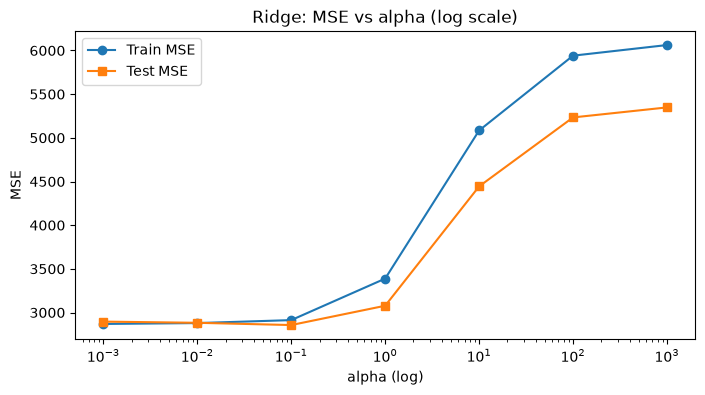

أفضل alpha (أقل Test MSE): 0.1


In [8]:
alphas = [0.001, 0.01, 0.1, 1, 10, 100, 1000]
train_mse, test_mse = [], []
for a in alphas:
    r = Ridge(alpha=a).fit(X_train, y_train)
    train_mse.append(mean_squared_error(y_train, r.predict(X_train)))
    test_mse.append(mean_squared_error(y_test, r.predict(X_test)))

plt.figure(figsize=(8,4))
plt.plot(alphas, train_mse, "o-", label="Train MSE")
plt.plot(alphas, test_mse, "s-", label="Test MSE")
plt.xscale("log")
plt.title("Ridge: MSE vs alpha (log scale)")
plt.xlabel("alpha (log)"); plt.ylabel("MSE"); plt.legend()
plt.show()
best_alpha = alphas[int(np.argmin(test_mse))]
print("أفضل alpha (أقل Test MSE):", best_alpha)

**تحليل الرسمة:** أفضل قيمة alpha ≈ **0.1** (أدنى Test MSE). عند alpha صغير جدًا
يتصرف Ridge مثل Linear العادي، وعند alpha كبير جدًا (100–1000) **ينهار الأداء**
ويرتفع خطأ التدريب والاختبار معًا — وهذا **Underfitting** بسبب العقوبة المفرطة.

## الجزء 5 — المقارنة الشاملة النهائية

In [9]:
# النماذج الأربعة على نفس بيانات الاختبار
# 1) Linear
# 2) Polynomial (bmi فقط، درجة 2)
Xb = df[['bmi']]
Xb_tr, Xb_te, yb_tr, yb_te = train_test_split(Xb, y, test_size=0.2, random_state=42)
pf = PolynomialFeatures(2)
poly_bmi = LinearRegression().fit(pf.fit_transform(Xb_tr), yb_tr)
pb = poly_bmi.predict(pf.transform(Xb_te))
poly_scores = {"MAE": mean_absolute_error(yb_te, pb), "MSE": mean_squared_error(yb_te, pb),
               "RMSE": mean_squared_error(yb_te, pb)**0.5, "R2": r2_score(yb_te, pb)}
# 3) Ridge أفضل alpha  4) Lasso alpha=1
ridge_best = Ridge(alpha=best_alpha).fit(X_train, y_train)

rows = {
    "Linear (كل المتغيرات)": scores(linear),
    "Polynomial (bmi، درجة 2)": poly_scores,
    f"Ridge (alpha={best_alpha})": scores(ridge_best),
    "Lasso (alpha=1.0)": scores(lasso),
}
final = pd.DataFrame(rows).T.round(3)
final

,MAE,MSE,RMSE,R2
Linear (كل المتغيرات),42.794,2900.194,53.853,0.453
Polynomial (bmi، درجة 2),52.384,4085.025,63.914,0.229
Ridge (alpha=0.1),42.997,2856.487,53.446,0.461
Lasso (alpha=1.0),49.730,3403.576,58.340,0.358


**النموذج الأفضل:** بالنظر إلى الأرقام الفعلية، **Ridge عند alpha=0.1** حقق أفضل
أداء: أدنى MSE/RMSE وأعلى R² (≈0.461)، متفوّقًا قليلًا على Linear العادي (0.453)،
وبفارق كبير عن Polynomial (bmi وحده، 0.229) وLasso (0.358).

**لماذا هذا النموذج؟** لأن diabetes فيه 10 متغيرات مترابطة قليلًا، فالانحدار الخطي
الكامل جيد لكنه عرضة لبعض المبالغة في المعاملات؛ Ridge بعقوبة **خفيفة** (alpha=0.1)
يصغّر المعاملات قليلًا فيقلّل التباين ويحسّن التعميم دون أن يفقد معلومات (لا يصفّر
متغيرات)، فجاء أفضل قليلًا من Linear. أما Lasso فصفّر متغيرات مفيدة هنا فخسر دقّة،
وPolynomial على متغيّر واحد أهمل بقية المتغيرات المهمة فكان الأضعف.

**لو كان عندي وقت أكثر:** كنت سأجرّب **Elastic Net** (يجمع L1+L2)، و**GridSearchCV**
لضبط alpha بدقّة أعلى، و**Feature Engineering** (تفاعلات بين المتغيرات وحدود
Polynomial على كل المتغيرات مع Regularization)، و**Cross-Validation** بدل تقسيم
واحد لنتيجة أكثر ثباتًا.